In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
from scipy.optimize import minimize
from scipy.optimize import approx_fprime
# numdifftools is not installed in the base env and nothing in this notebook needs it;
# `pip install numdifftools` and re-add the import if you later want Hessian-based intervals.

import importlib

%config InlineBackend.figure_format = 'retina'
cmap = plt.cm.viridis
cmap2 = plt.cm.twilight
rng = np.random.default_rng(seed=326890)   # PCG64 by default
cm = 1 / 2.54

# use color cmap(0.2), cmap(0.6)
# Desired axes dimensions in centimeters
axes_width_cm = 6.5
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.6
right_margin = 0.2
bottom_margin = 0.6
top_margin = 0.2

# save figures in pdf

## Figure 2 — inferred diffusivity vs injected measurement noise

Source: `data/sweep_results.parquet`, written by `NoiseInjectionSweep.py` (`run_sweep`).
The shipped file is the full study grid; `python NoiseInjectionSweep.py --no-resume --outdir data_regen`
recomputes the cells drawn here from scratch.
One row per fit: (`sigma_add`) × (`N_INF`) × (8 realizations) × (init mode) — 1872 fits,
Cartesian injection only (no `mode` column, so no `angle` control).

### Choosing the budgets

Four constants at the top of the next cell drive **both** figures:

| constant | meaning |
|---|---|
| `N_FIG1` | the single `N_INF` drawn in **Figure 2** |
| `N_FIG2B` | exactly three `N_INF` drawn in **Figure 2b** |
| `FIG2B_TOP` | which of the three draws on top (`None` = smallest `N`) |
| `ERR_KIND` | `'laplace'`, `'replicate'` or `'auto'` |

Available: `N_INF ∈ {2000, 4000, 8000, 16000, 32000, 64000, 128000, 256000, 512000}` —
≈6 to ≈1630 cycles ($T = 40$ to $10240$).
Bad picks fail immediately with a message naming the fix, and each figure asserts its data
fits the frame rather than clipping silently (widen `YLIM` / `YLIM_2B` if it fires).

### Error bars — read before switching budgets

The sweep does **not** compute the Laplace covariance everywhere (`cov_all_below` /
`n_cov_reps` in the grid signature):

| `N_INF` | realizations carrying `lnD_std` | `'auto'` gives |
|---|---|---|
| 2000, 4000, 8000 | 8 of 8 | Laplace 95 % |
| 16000, 32000 | **2 of 8** | Laplace 95 %, averaged over 2 fits |
| 64000 and above | **0 of 8** | **replicate 95 %** |

So `ERR_KIND = 'laplace'` raises at the two largest budgets, and at 16000/32000 the Laplace
bar rests on only 2 of the 8 fits.

**`ERR_KIND = 'replicate'` is the committed setting**, and it is not a fallback. Both figures
now draw budgets on either side of the covariance boundary, and `'auto'` would silently give
the small budgets Laplace bars and the large ones replicate bars — two different quantities on
one axis with nothing to distinguish them. Figure 2b asserts that all its series carry the same
kind. The cost is an 8-sample estimate of the spread.

How much that costs depends on the budget, and Figure 2 prints the comparison rather than
asserting it. The replicate/Laplace ratio tightens monotonically with `N` — `0.59–0.99` at 2000,
`0.76–1.08` at 8000, `0.92–1.06` at 32000 — so at the budgets these figures actually draw the
two intervals are close, while at `N=2000` they differ by up to 40 % (in both directions,
depending on `σ`). The replicate bars on the `N=2000` series are therefore doing real work: they
report the realization-to-realization scatter that a short record genuinely has, which the
Laplace interval, being a within-fit quantity, does not see.

Note the two intervals answer different questions: Laplace is *within-fit precision under the
surrogate's own (misspecified) model*, replicate is *how far the answer moves between
realizations*. Where both exist they agree to within a few percent below `R_add ≈ 0.1`.

### The panel

`default` initialization, `N_FIG1` (`T = (N_FIG1 - 1) * 0.02`; `T = 640`, ≈102 cycles at the
committed 32000), **untruncated**: `R_MAX = 1.0` keeps all thirteen `sigma_add` levels, so
`R_add` runs 0 → 1. Set `R_MAX = 0.1` to cut back to the linearisation-valid range instead; the
x-limits and ticks follow either way.

- **x** — `R_add = sigma_add**2`, the injected variance per Cartesian component: the quantity
  the surrogate's isotropic `R` is supposed to absorb. `symlog` below `1e-4` so the
  un-injected case sits at a true 0.
- **y** — `D_map`, the MAP phase diffusivity [rad²/time], **geometric** mean over the 8
  realizations, since EM fits `log D`.
- **error bars** — as above; symmetric in `log D`, so asymmetric in linear `D`.
- **reference lines** — `D_x = 1e-3` (short-lag slope/2, dotted) and
  `D_eff = D_x (1 + b²/a²) = 2e-3` (long-lag slope/2, dashed — the target).

### Output geometry

Written as `.pdf`, `.svg` and `.png` at **one physical size**, matched to
the companion `StuartLandau_AmplitudeAutocovariance.pdf` panel: a
**3.5 × 2.8 cm** axes frame inside a **6.50 × 4.30 cm** figure, margins
`(1.5, 1.5, 1.0, 0.5)` cm. Both notebooks leave `rcParams` alone, so the typography already
agreed (8 pt labels, 7 pt ticks and legend, 0.5 pt spines and inward ticks); what changed here
is the frame size and the data stroke, dropped from 1 pt to the reference's 0.5 pt. Nothing is
saved with `bbox_inches='tight'` — that would crop each format to its own ink extent and the
three would stop agreeing.

Two consequences of the smaller frame, both cosmetic: `linscale` rises to 1.0 (Figure 2b keeps
0.35) so the `0` and `10⁻⁴` labels do not overlap, and only every other decade is labelled, the
rest drawn as unlabelled minor ticks.

Styling otherwise comes from `figstyle.py` (the house style shared with the GlycolyticOscillator example).
Figure 2b is unchanged and still draws at 6.5 × 4.5 cm.


In [2]:
from pathlib import Path

# ══════════════════════════════════════════════════════════════════════════════════════════
# PICK THE BUDGETS HERE — everything below follows from these four lines.
# ══════════════════════════════════════════════════════════════════════════════════════════
N_FIG1 = 32000                        # the single N_INF drawn in Figure 2
N_FIG2B = (2000, 8000, 32000)         # the three N_INF drawn in Figure 2b
FIG2B_TOP = 32000                     # which of the three draws on top (None = smallest N)
ERR_KIND = 'replicate'                 # error bars: 'laplace' | 'replicate' | 'auto'
# 'replicate' is committed rather than derived. The sweep computes no Laplace covariance
# above N_INF = 32000, so 'auto' would hand Laplace bars to the small budgets and replicate
# bars to the large ones -- two different quantities on one axis, with nothing in the figure
# to tell them apart. Laplace is within-fit precision under the surrogate's own (misspecified)
# model; replicate is how far the answer moves between realizations. Forcing 'replicate'
# makes every series on both figures mean the same thing.
# ══════════════════════════════════════════════════════════════════════════════════════════

# ── physics: NoiseInjectionSweep.Config (a, b, Dx) and its derived quantities ───────────
a, b, Dx = 1.0, 1.0, 1e-3             # [1/time], [dimensionless], [length^2/time]
D_eff = Dx * (1.0 + b**2 / a**2)      # 2e-3 rad^2/time  — long-time phase diffusivity
tau_r = 1.0 / (2.0 * a)               # 0.5 time         — radial relaxation time
sigma_rho = np.sqrt(Dx / (2.0 * a))   # rms radial fluctuation [length]

SWEEP = Path('data') / 'sweep_results.parquet'
INIT = 'default'


def dmap_vs_noise(n_inf, init=INIT, path=SWEEP):
    """Replicate-aggregated D_map as a function of the injected noise variance.

    The current sweep is Cartesian-injection only (``y <- y + sigma_add * N(0, I_2)``), so
    there is no ``mode`` column. Older parquets carried one, with an ``'angle'`` control
    alongside; those are filtered down to ``'cartesian'`` so this function reads either.

    Parameters
    ----------
    n_inf : int
        Number of inference points; must exist in the cached grid.
    init : {'default', 'informed'}
        EM initialization used by the sweep.
    path : Path
        Parquet written by ``NoiseInjectionSweep.run_sweep``.

    Returns
    -------
    pandas.DataFrame
        One row per ``sigma_add``. ``R_add`` [rad^2] is the injected variance;
        ``D_gmean``/``D_gsd`` are the geometric mean and geometric sd of ``D_map`` over the
        realizations; ``lap_lo``/``lap_hi`` are the mean Laplace 95 % interval and are NaN
        where the sweep computed no covariance; ``rep_lo``/``rep_hi`` are the **95 %**
        replicate interval (``D_gsd ** ±1.96``); ``n_cov`` counts realizations that actually
        carry a Laplace sd; ``n`` counts realizations; ``all_converged`` flags the EM cap.
    """
    df = pd.read_parquet(path)
    if 'mode' in df.columns:                       # back-compat with the pre-2026-08-10 grid
        df = df[df['mode'] == 'cartesian']
    q = df[(df['init_mode'] == init) & (df['N_INF'] == n_inf)]
    if q.empty:
        raise ValueError(f'no rows for init={init!r}, N_INF={n_inf}; '
                         f'available N_INF = {sorted(df["N_INF"].unique())}')

    g = q.groupby('sigma_add').agg(
        D_gmean=('D_map', lambda s: np.exp(np.log(s).mean())),
        D_gsd=('D_map', lambda s: np.exp(np.log(s).std(ddof=1))),
        lnD_std=('lnD_std', 'mean'),               # skips NaN; NaN only if no rep has one
        n_cov=('lnD_std', lambda s: int(s.notna().sum())),
        n=('D_map', 'size'),
        all_converged=('converged', 'all'),
    ).reset_index()

    g['R_add'] = g['sigma_add'].values ** 2
    g['lap_lo'] = g['D_gmean'] * np.exp(-1.96 * g['lnD_std'])
    g['lap_hi'] = g['D_gmean'] * np.exp(+1.96 * g['lnD_std'])
    g['rep_lo'] = g['D_gmean'] / g['D_gsd'] ** 1.96
    g['rep_hi'] = g['D_gmean'] * g['D_gsd'] ** 1.96
    return g


def err_bounds(gi, kind=None):
    """Error-bar bounds for one aggregated frame, and a label for what they are.

    The sweep only computes the Laplace covariance for a subset of realizations
    (``cov_all_below`` / ``n_cov_reps`` in the grid signature), and for the largest budgets
    it computes none at all. ``'auto'`` therefore falls back to the replicate interval,
    which is available at every budget, rather than plotting NaN.

    Parameters
    ----------
    gi : pandas.DataFrame
        A frame from :func:`dmap_vs_noise`.
    kind : {'laplace', 'replicate', 'auto', None}
        ``None`` uses the module-level ``ERR_KIND``.

    Returns
    -------
    (lo, hi, label) : (ndarray, ndarray, str)
    """
    kind = ERR_KIND if kind is None else kind
    have_lap = int(gi['n_cov'].min()) > 0
    if kind == 'auto':
        kind = 'laplace' if have_lap else 'replicate'
    if kind == 'laplace':
        if not have_lap:
            raise ValueError('no Laplace covariance at this budget; use "replicate"')
        n_lo, n_hi = int(gi['n_cov'].min()), int(gi['n_cov'].max())
        span = f'{n_lo}' if n_lo == n_hi else f'{n_lo}-{n_hi}'
        return (gi['lap_lo'].values, gi['lap_hi'].values,
                f'Laplace 95% ({span} of {int(gi["n"].iloc[0])} reps)')
    return (gi['rep_lo'].values, gi['rep_hi'].values,
            f'replicate 95% ({int(gi["n"].iloc[0])} reps)')


# What the cached sweep actually contains, so a regenerated parquet cannot change the
# figures silently.
_raw = pd.read_parquet(SWEEP)
AVAILABLE_N = sorted(int(v) for v in _raw['N_INF'].unique())
print(f'{SWEEP}: {len(_raw)} fits, {(~_raw["converged"]).sum()} hit the EM cap')
print(f'  N_INF grid  = {AVAILABLE_N}')
print(f'  sigma grid  = {[float(v) for v in sorted(_raw["sigma_add"].unique())]}')
print(f'  init modes  = {sorted(_raw["init_mode"].unique())}, '
      f'{_raw["rep"].nunique()} realizations each')

# Validate the picks up front, with a message that names the fix.
assert N_FIG1 in AVAILABLE_N, f'N_FIG1={N_FIG1} not in {AVAILABLE_N}'
assert len(N_FIG2B) == 3, f'N_FIG2B must name exactly three budgets, got {len(N_FIG2B)}'
assert all(n in AVAILABLE_N for n in N_FIG2B), f'N_FIG2B={N_FIG2B} not all in {AVAILABLE_N}'
assert FIG2B_TOP is None or FIG2B_TOP in N_FIG2B, f'FIG2B_TOP={FIG2B_TOP} not in {N_FIG2B}'

# How many realizations carry a Laplace covariance at each budget -- this decides whether
# 'auto' gives Laplace or replicate bars, so it is reported rather than discovered later.
print(f'\n{"N_INF":>7} {"reps with Laplace cov":>22}  ->  auto error bars')
for n in AVAILABLE_N:
    gi = dmap_vs_noise(n)
    print(f'{n:>7} {int(gi["n_cov"].min()):>13} of {int(gi["n"].iloc[0]):<6}'
          f'  ->  {err_bounds(gi, "auto")[2]}')
print()

g = dmap_vs_noise(N_FIG1)
assert g['all_converged'].all(), 'some EM fits hit the iteration cap — D_map unreliable'
print(f'Figure 2: Cartesian injection, {INIT} init, N_INF={N_FIG1}, '
      f'{g["n"].iloc[0]} realizations per point\n')
print(g[['sigma_add', 'R_add', 'D_gmean', 'D_gsd', 'lnD_std', 'n_cov',
         'lap_lo', 'lap_hi', 'rep_lo', 'rep_hi']]
      .to_string(index=False, float_format=lambda v: f'{v:.4g}'))
print(f'\nD_x = {Dx:.3e},  D_eff = {D_eff:.3e}')

data/sweep_results.parquet: 1872 fits, 0 hit the EM cap
  N_INF grid  = [2000, 4000, 8000, 16000, 32000, 64000, 128000, 256000, 512000]
  sigma grid  = [0.0, 0.01, 0.02, 0.03, 0.045, 0.06, 0.08, 0.1, 0.15, 0.2, 0.3, 0.5, 1.0]
  init modes  = ['default', 'informed'], 8 realizations each

  N_INF  reps with Laplace cov  ->  auto error bars
   2000             8 of 8       ->  Laplace 95% (8 of 8 reps)
   4000             8 of 8       ->  Laplace 95% (8 of 8 reps)
   8000             8 of 8       ->  Laplace 95% (8 of 8 reps)
  16000             2 of 8       ->  Laplace 95% (2 of 8 reps)
  32000             2 of 8       ->  Laplace 95% (2 of 8 reps)
  64000             0 of 8       ->  replicate 95% (8 reps)
 128000             0 of 8       ->  replicate 95% (8 reps)
 256000             0 of 8       ->  replicate 95% (8 reps)


 512000             0 of 8       ->  replicate 95% (8 reps)

Figure 2: Cartesian injection, default init, N_INF=32000, 8 realizations per point

 sigma_add    R_add   D_gmean  D_gsd  lnD_std  n_cov    lap_lo    lap_hi    rep_lo    rep_hi
         0        0 0.0006246  1.028  0.02006      2 0.0006005 0.0006496 0.0005922 0.0006587
      0.01   0.0001 0.0007213  1.031  0.02227      2 0.0006905 0.0007535 0.0006798 0.0007654
      0.02   0.0004 0.0009184  1.032  0.02673      2 0.0008715 0.0009678 0.0008626 0.0009777
      0.03   0.0009  0.001074  1.035  0.03147      2   0.00101  0.001142  0.001004  0.001149
     0.045 0.002025  0.001254  1.048   0.0376      2  0.001165   0.00135  0.001145  0.001374
      0.06   0.0036  0.001339  1.038  0.04291      2  0.001231  0.001457  0.001245  0.001441
      0.08   0.0064  0.001451  1.047  0.04884      2  0.001319  0.001597  0.001327  0.001586
       0.1     0.01  0.001556  1.082  0.05405      2    0.0014   0.00173  0.001333  0.001817
      0.15   0.022

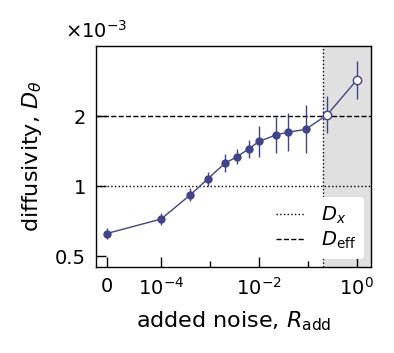

figure 6.50 x 4.30 cm (axes 3.5 x 2.8 cm) -- StuartLandau_AmplitudeAutocovariance.pdf is 6.50 x 4.30 cm
wrote plots/figure2_Dmap_vs_Radd.pdf, .svg, .png
N_INF = 32000, error bars = replicate 95% (8 reps)
plotted 13 of 13 noise levels (R_add <= 1); nothing dropped
shaded R_add > 0.2: 2 point(s) drawn open at R_add = 0.25, 1
D_map(R_add=0)      = 6.246e-04  = 0.62 D_x   (below D_x: over-smoothed)
D_map(R_add=1)   = 2.859e-03  = 1.43 D_eff
over the plotted range D_map/D_eff spans 0.31 to 1.43
unshaded range only (R_add <= 0.2): 0.31 to 0.88 D_eff

replicate 95% / Laplace 95% at this budget: min 0.92, max 1.06 -- the two agree, so 'replicate' loses nothing


In [3]:
import matplotlib as mpl

import figstyle as fs   # house style shared with the GlycolyticOscillator example

R_MAX = 1.0                 # injected-variance range kept; 1.0 is the whole sweep, nothing dropped
YLIM = (4.5e-4, 4.0e-3)     # headroom above the R_add = 1 bar (3.455e-3 at N_INF = 32000)

# ── geometry and weights taken from the PhaseReduction notebook ─────────────────────────
# (the cell that writes StuartLandau_AmplitudeAutocovariance.pdf), so this panel and that one
# drop into the paper at the same scale with no rescaling. That cell builds a fixed axes box
# with margins in cm; figstyle.figax takes them in inches, hence the * fs.CM.
# Checked against the reference PDF: media box 184.25 x 121.89 pt = 6.50 x 4.30 cm.
AX_W_CM, AX_H_CM = 3.5, 2.8            # axes frame  (was 6.5 x 4.5)
MARGINS_CM = (1.5, 1.5, 1.0, 0.5)      # left, right, bottom, top -> 6.50 x 4.30 cm figure
LW_LINE = 0.5                          # every stroke in the reference is 0.5 pt
# Typography needs no work: neither notebook touches rcParams, so both are on the matplotlib
# default face, and figstyle's FS_LABEL/FS_TICK/FS_LEGEND/LW_SPINE (8/7/7/0.5 pt, ticks
# inward at 0.5 pt) are already the values that cell sets by hand.

# ── the shaded region ────────────────────────────────────────────────────────────────────
# R_add > R_SHADE is drawn on grey with open markers: injection that large is no longer a
# small perturbation of the limit cycle (at R_add = 1 the measured radius is rbar = 1.55, and
# sigma_psi is outside the range the EKF linearises over), so the fits there are marked as
# outside the surrogate's regime rather than dropped. Nothing about the data changes.
R_SHADE = 0.2                          # [rad^2] injected variance
C_SHADE = '0.88'                       # neutral grey; survives greyscale printing
# ══════════════════════════════════════════════════════════════════════════════════════════

gp = g[g['R_add'] <= R_MAX].reset_index(drop=True)
lo, hi, err_label = err_bounds(gp)

fig, ax = fs.figax(AX_W_CM, AX_H_CM, margins_in=tuple(m * fs.CM for m in MARGINS_CM))

# reference diffusivities: house GUIDE spec (k, 0.5 pt), dotted for D_x to separate the two
h_x = ax.axhline(Dx, **{**fs.GUIDE, 'ls': ':'}, zorder=1, label=r'$D_x$')
h_eff = ax.axhline(D_eff, **fs.GUIDE, zorder=1, label=r'$D_{\rm eff}$')

x = gp['R_add'].values
D = gp['D_gmean'].values

# lw=LW_LINE rather than fs.MEAN (1 pt): the reference draws its curves at 0.5 pt, and in a
# 3.5 cm frame a 1 pt trace reads much heavier than the panel it sits beside.
ax.errorbar(x, D, yerr=[D - lo, hi - D], fmt='o-', ms=3, mew=0, lw=LW_LINE,
            color=fs.C_DATA, mfc=fs.C_DATA, capsize=0, elinewidth=LW_LINE, zorder=3,
            label=rf'$N_{{\rm INF}}={N_FIG1}$')

# The points beyond R_SHADE redrawn open: white face, same C_DATA edge. Overplotted rather
# than split into two errorbar calls, so the connecting line and the bars stay continuous.
beyond = x > R_SHADE
ax.plot(x[beyond], D[beyond], ls='none', marker='o', ms=3,
        mfc='white', mec=fs.C_DATA, mew=LW_LINE, zorder=4)

# symlog keeps the un-injected fit (R_add = 0) at a true zero instead of hiding it.
# linscale = 1.0 -- Figure 2b keeps 0.35, but in a 3.5 cm frame that narrow a linear segment
# lands the '0' label on top of the '10^-4' one.
ax.set_xscale('symlog', linthresh=1e-4, linscale=1.0)
ax.set_yscale('log')
ax.set_xlim(-0.2e-4, 2.0 if R_MAX > 0.1 else 0.2)
ax.set_ylim(*YLIM)

# Shade from R_SHADE to the right spine. Taken from get_xlim() rather than written as a
# literal so the band still reaches the edge if R_MAX or the limits change; zorder=0 puts it
# under the guide lines and the data. Drawn after set_xlim, which is what it reads.
ax.axvspan(R_SHADE, ax.get_xlim()[1], facecolor=C_SHADE, lw=0, zorder=0)
ax.axvline(R_SHADE, **{**fs.GUIDE, 'ls': ':'}, zorder=2)

# Every other decade carries a label, the rest are unlabelled minor ticks: six labelled
# decades do not fit across 3.5 cm at 7 pt, and dropping the ticks outright would coarsen
# the scale the reader reads positions off.
if R_MAX > 0.1:
    xt, xt_minor = [0, 1e-4, 1e-2, 1e0], [1e-3, 1e-1]
else:
    xt, xt_minor = [0, 1e-3, 1e-1], [1e-4, 1e-2]
ax.set_xticks(xt)
ax.set_xticklabels(['0'] + [rf'$10^{{{int(np.log10(t))}}}$' for t in xt[1:]])
ax.set_xticks(xt_minor, minor=True)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())

# y in units of 1e-3, with the decade factored out above the axis
ax.set_yticks([5e-4, 1e-3, 2e-3])
ax.set_yticklabels(['0.5', '1', '2'])
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
ax.text(0.0, 1.02, r'$\times10^{-3}$', transform=ax.transAxes,
        fontsize=fs.FS_TICK, ha='center', va='bottom')

# house tick/spine/label styling: 8 pt labels, 7 pt ticks, 0.5 pt inward ticks and spines
fs.style_axes(ax, xlabel=r'added noise, $R_{\rm add}$', ylabel=r'diffusivity, $D_{\theta}$')

# Only the two reference levels go in the legend; the data series is self-evident. Boxed on
# opaque white, as the reference legend is, because at this size it sits over the curve.
fs.legend(ax, boxed=True, handles=[h_x, h_eff], loc='lower right', facecolor='white',
          framealpha=1.0, handlelength=1.5, labelspacing=0.2, borderaxespad=0.4)

# Check the frame BEFORE writing: a clipped figure that reaches plots/ can be picked up by
# the paper, and an assertion after the save reports the problem too late to prevent that.
assert YLIM[0] <= lo.min() and hi.max() <= YLIM[1], (
    f'N_INF={N_FIG1} spans [{lo.min():.3e}, {hi.max():.3e}] — widen YLIM')

# One physical size for all three formats. No bbox_inches on any of them: 'tight' crops each
# format to its own ink extent, and the three would stop agreeing with each other and with
# the reference. The PNG differs from the vector pair only in raster density.
STEM = Path('plots') / 'figure2_Dmap_vs_Radd'
fs.save(fig, STEM.with_suffix('.pdf'))
fig.savefig(STEM.with_suffix('.svg'))
fig.savefig(STEM.with_suffix('.png'), dpi=400)   # screen copy only
plt.show()

_w_cm, _h_cm = (v * 2.54 for v in fig.get_size_inches())
print(f"figure {_w_cm:.2f} x {_h_cm:.2f} cm (axes {AX_W_CM} x {AX_H_CM} cm) -- "
      f"StuartLandau_AmplitudeAutocovariance.pdf is 6.50 x 4.30 cm")
print(f"wrote {STEM}.pdf, .svg, .png")
print(f"N_INF = {N_FIG1}, error bars = {err_label}")
print(f"plotted {len(gp)} of {len(g)} noise levels (R_add <= {R_MAX:g})"
      + (f"; dropped sigma_add = "
         f"{', '.join(f'{s:g}' for s in g.loc[g['R_add'] > R_MAX, 'sigma_add'])}"
         if (g['R_add'] > R_MAX).any() else '; nothing dropped'))
print(f"shaded R_add > {R_SHADE:g}: {beyond.sum()} point(s) drawn open at R_add = "
      + ', '.join(f'{v:g}' for v in x[beyond]))
print(f"D_map(R_add=0)      = {D[0]:.3e}  = {D[0]/Dx:.2f} D_x   (below D_x: over-smoothed)")
print(f"D_map(R_add={x[-1]:.3g})   = {D[-1]:.3e}  = {D[-1]/D_eff:.2f} D_eff")
print(f"over the plotted range D_map/D_eff spans {D.min()/D_eff:.2f} to {D.max()/D_eff:.2f}")
print(f"unshaded range only (R_add <= {R_SHADE:g}): "
      f"{D[~beyond].min()/D_eff:.2f} to {D[~beyond].max()/D_eff:.2f} D_eff")

# Justification for committing to the replicate interval: where both exist they agree, so
# nothing is lost by using the one that is available at every budget. Ratio > 1 means the
# Laplace bars understate the spread a rerun would actually give.
if int(gp['n_cov'].min()) > 0:
    ratio = (gp['D_gsd'] ** 1.96) / np.exp(1.96 * gp['lnD_std'])
    print(f"\nreplicate 95% / Laplace 95% at this budget: min {ratio.min():.2f}, "
          f"max {ratio.max():.2f} -- the two agree, so 'replicate' loses nothing")
else:
    print(f"\nN_INF={N_FIG1} is above the sweep's cov_max_N, so no Laplace covariance exists "
          f"here at all; the replicate interval is the only one this budget supports.")
    # How much the choice costs, at every budget that carries both. Reported in full rather
    # than summarised from one budget: the agreement is a strong function of N, so a single
    # number would overstate it.
    print("replicate 95% / Laplace 95%, where both exist:")
    for _n in AVAILABLE_N:
        _g = dmap_vs_noise(_n)
        if int(_g['n_cov'].min()) == 0:
            continue
        _r = (_g['D_gsd'] ** 1.96) / np.exp(1.96 * _g['lnD_std'])
        print(f"    N_INF = {_n:>6}: {_r.min():.2f}-{_r.max():.2f}")
    print("Ratio < 1 means the Laplace interval is the wider of the two. The agreement tightens\n"
          "with N, so at the budgets these figures draw the choice is nearly free; at N=2000 it\n"
          "is not, and there the replicate bars are the ones reporting the real scatter.")

## Figure 2b — the full injected-noise range, at three data budgets

> **Note.** The table and bullets below were written with `N_FIG2B = (2000, 8000, 512000)`. The
> committed setting draws `(2000, 8000, 32000)`; the 512000 numbers are still in the shipped
> `data/sweep_results.parquet` and are reproduced by setting `N_FIG2B` accordingly (widen `YLIM_2B`
> if the frame assertion fires). The cell below prints the table for whatever is selected.

Same data, same aggregation, nothing truncated: all thirteen `sigma_add` levels, so `R_add`
runs 0 → 1. The three budgets come from `N_FIG2B` in the setup cell; `FIG2B_COLORS` below
gives one colour per entry, **in that order**, so re-picking the budgets keeps the colours
predictable. With the committed choice:

| `N_INF` | colour | window | cycles |
|---|---|---|---|
| 2000 | `cmap(0.6)` | `T = 40` | ≈6 |
| 8000 | `cmap(0.2)` | `T = 160` | ≈25 |
| 512000 | `cmap(0.85)` | `T = 10240` | ≈1630 |

They span a **256× range in observation window**, the widest the sweep supports. Each series
calls `dmap_vs_noise(n)` for its own frame, so a legend entry can never disagree with the data
it draws. `FIG2B_TOP` decides which series sits above the others where they overlap.

What the three budgets show (`D_map/D_eff`):

| `R_add` | 2000 | 8000 | 512000 |
|---|---|---|---|
| 0 | 0.29 | 0.31 | 0.31 |
| 0.01 | 0.65 | 0.77 | 0.77 |
| 0.09 | 0.85 | 0.85 | **0.91** |
| 0.25 | 1.39 | 1.14 | **0.97** |
| 1 | 4.15 | 2.29 | **1.02** |

- **There is no plateau at the right answer.** No feature of any curve tells you which injection
  level to trust — the point of the figure, and it survives the extra data.
- **Below `R_add ≈ 0.1` the centres move only weakly with `N`, and they stop.** At `R_add = 0.01`
  they go `0.65 → 0.77` and then nothing: `T = 2560 → 10240` moves that row by under 1 %. So 256×
  the data leaves the estimate a quarter short of `D_eff`.
- **The large-injection overshoot is a short-window artefact.** At `R_add = 1` it falls
  `4.15 → 2.29 → 1.02`. The `T = 10240` curve does not overshoot within the plotted range at all:
  it reaches `0.97` at `R_add = 0.25` and `1.02` at `R_add = 1`.

That last row is the interesting one. The longest record lands on `D_eff` at large injection —
the pseudo-true value `D*(σ)` climbs to `0.996 D_eff` by `σ_ψ ≈ 1.1` rad, and the measurement
follows it there. Injection *can* recover `D_eff`; what it cannot do is recover it at a noise
level where the filter's own model still holds. At `R_add = 0.09` (`σ_ψ = 0.32` rad, the largest
value inside the EKF's linearisation) the converged answer is `0.91 D_eff` — ten standard
deviations short. At `R_add = 1` the measured radius is `r̄ = 1.55`, so the "correct" number is
obtained from a measurement that is no longer a perturbed limit cycle.

The cell prints a per-budget table of `D_map/D_eff` and a pinned-vs-converging verdict at four
noise levels, so both claims stay checkable when the budgets change.


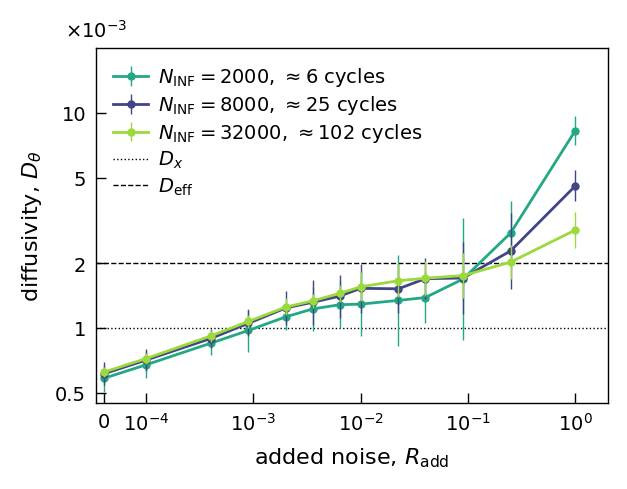

plotted budgets: 2000, 8000, 32000   (top = 32000)
  N_INF =   2000: error bars = replicate 95% (8 reps)
  N_INF =   8000: error bars = replicate 95% (8 reps)
  N_INF =  32000: error bars = replicate 95% (8 reps)

N_INF =   2000: T =    39.98,    6.36 cycles,    80 radial relaxation times, 0.080 of a phase-decorrelation time
N_INF =   8000: T =   159.98,   25.46 cycles,   320 radial relaxation times, 0.320 of a phase-decorrelation time
N_INF =  32000: T =   639.98,  101.86 cycles,  1280 radial relaxation times, 1.280 of a phase-decorrelation time

   R_add |     2000     8000    32000   (D_map/D_eff)
-------------------------------------
       0 |     0.29     0.31     0.31
  0.0001 |     0.34     0.35     0.36
  0.0004 |     0.42     0.45     0.46
  0.0009 |     0.49     0.53     0.54
0.002025 |     0.56     0.62     0.63
  0.0036 |     0.61     0.66     0.67
  0.0064 |     0.64     0.70     0.73
    0.01 |     0.65     0.77     0.78
  0.0225 |     0.67     0.76     0.83
    0.04 |  

In [4]:
DT_INF = 0.02       # inference sample spacing [time] — cfg.delta_t_inf
OMEGA_0 = 1.0       # nominal angular frequency [rad/time]; the noise-induced shift is <0.25 %

# one colour per entry of N_FIG2B, in that order
FIG2B_COLORS = (fs.C_MODEL, fs.C_DATA, cmap(0.85))
YLIM_2B = (4.5e-4, 2.0e-2)


def n_cycles(n_inf, dt_inf=DT_INF, omega=OMEGA_0):
    """Oscillation cycles spanned by an inference window.

    Parameters
    ----------
    n_inf : int
        Number of inference samples.
    dt_inf : float
        Spacing between samples [time].
    omega : float
        Angular frequency [rad/time].

    Returns
    -------
    float
        ``T / (2 pi / omega)`` with ``T = (n_inf - 1) * dt_inf``.
    """
    return (n_inf - 1) * dt_inf * omega / (2 * np.pi)


# Each series fetches its own frame, so a label can never disagree with the data it draws.
# zorder puts FIG2B_TOP above the rest; the others stack in the order given.
_top = FIG2B_TOP if FIG2B_TOP is not None else min(N_FIG2B)
SERIES = [(n, dmap_vs_noise(n), c, 10 if n == _top else 3 + i)
          for i, (n, c) in enumerate(zip(N_FIG2B, FIG2B_COLORS))]

for n_inf, gi, *_ in SERIES:
    assert gi['all_converged'].all(), f'some N={n_inf} EM fits hit the iteration cap'

fig, ax = fs.figax(6.5, 4.5)

h_x = ax.axhline(Dx, **{**fs.GUIDE, 'ls': ':'}, zorder=1, label=r'$D_x$')
h_eff = ax.axhline(D_eff, **fs.GUIDE, zorder=1, label=r'$D_{\rm eff}$')

handles, err_labels = [], []
for n_inf, gi, colour, z in SERIES:
    xi, Di = gi['R_add'].values, gi['D_gmean'].values
    lo_i, hi_i, lab_i = err_bounds(gi)
    err_labels.append((n_inf, lab_i))
    h = ax.errorbar(xi, Di, yerr=[Di - lo_i, hi_i - Di],
                    fmt='o-', ms=3, mew=0, color=colour, mfc=colour,
                    capsize=0, elinewidth=0.5, zorder=z, **fs.MEAN,
                    label=rf'$N_{{\rm INF}}={n_inf}$, $\approx${n_cycles(n_inf):.0f} cycles')
    handles.append(h)

ax.set_xscale('symlog', linthresh=1e-4, linscale=0.35)
ax.set_yscale('log')
ax.set_xlim(-0.2e-4, 2.0)
ax.set_ylim(*YLIM_2B)

ax.set_xticks([0, 1e-4, 1e-3, 1e-2, 1e-1, 1e0])
ax.set_xticklabels(['0', r'$10^{-4}$', r'$10^{-3}$', r'$10^{-2}$', r'$10^{-1}$', r'$10^{0}$'])

# same y convention as Figure 2: units of 1e-3, decade factored out above the axis
ax.set_yticks([5e-4, 1e-3, 2e-3, 5e-3, 1e-2])
ax.set_yticklabels(['0.5', '1', '2', '5', '10'])
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
ax.text(0.0, 1.02, r'$\times10^{-3}$', transform=ax.transAxes,
        fontsize=fs.FS_TICK, ha='center', va='bottom')

fs.style_axes(ax, xlabel=r'added noise, $R_{\rm add}$', ylabel=r'diffusivity, $D_{\theta}$')

fs.legend(ax, handles=handles + [h_x, h_eff], loc='upper left',
          handlelength=1.8, handletextpad=0.5, labelspacing=0.25, borderaxespad=0.5)

# Guard the axis limits BEFORE writing, so a budget choice that does not fit the frame can
# never leave a clipped PDF in plots/ for the paper to pick up.
for n_inf, gi, *_ in SERIES:
    lo_i, hi_i, _ = err_bounds(gi)
    assert YLIM_2B[0] <= lo_i.min() and hi_i.max() <= YLIM_2B[1], (
        f'N_INF={n_inf} spans [{lo_i.min():.3e}, {hi_i.max():.3e}] — widen YLIM_2B')

# Every series must carry the same kind of interval, or the figure compares two different
# quantities without saying so.
_kinds = {lab.split()[0] for _, lab in err_labels}
assert len(_kinds) == 1, f'mixed error-bar kinds across series: {err_labels}'

fs.save(fig, Path('plots') / 'figure2b_Dmap_vs_Radd_full.pdf')
fig.savefig(Path('plots') / 'figure2b_Dmap_vs_Radd_full.png', dpi=400)
plt.show()

print(f'plotted budgets: {", ".join(str(n) for n, *_ in SERIES)}   (top = {_top})')
for n_inf, lab in err_labels:
    print(f'  N_INF = {n_inf:6d}: error bars = {lab}')

print()
for n_inf, *_ in SERIES:
    T = (n_inf - 1) * DT_INF
    print(f"N_INF = {n_inf:6d}: T = {T:8.2f}, {n_cycles(n_inf):7.2f} cycles, "
          f"{T/tau_r:5.0f} radial relaxation times, "
          f"{T*D_eff:.3f} of a phase-decorrelation time")

# D/D_eff for every plotted budget, side by side at each noise level
print(f"\n{'R_add':>8} | " + ' '.join(f'{n:>8}' for n, *_ in SERIES) + '   (D_map/D_eff)')
print('-' * (10 + 9 * len(SERIES)))
for i, r_add in enumerate(SERIES[0][1]['R_add']):
    row = ' '.join(f'{gi["D_gmean"].iloc[i]/D_eff:>8.2f}' for _, gi, *_ in SERIES)
    print(f"{r_add:>8.4g} | {row}")

print()
for n_inf, gi, *_ in SERIES:
    cross = gi.loc[gi['D_gmean'] >= D_eff, 'R_add']
    where = f'{cross.iloc[0]:.3g}' if len(cross) else 'never'
    print(f"N_INF = {n_inf:6d}: first reaches D_eff at R_add = {where}, "
          f"ends at {gi['D_gmean'].iloc[-1]/D_eff:.2f} D_eff")

# H1 check: at small injection the centres should be pinned; at large injection watch whether
# they march toward 1 as N grows -- that would be statistics, not bias.
ns = [n for n, *_ in SERIES]
print()
for r_add in (0.0, 0.01, 0.09, 1.0):
    vals = [gi.loc[gi['R_add'].sub(r_add).abs().idxmin(), 'D_gmean']/D_eff
            for _, gi, *_ in SERIES]
    trend = 'converging' if abs(vals[-1] - 1) < abs(vals[0] - 1) - 0.05 else 'pinned'
    print(f"R_add = {r_add:<5g}: D/D_eff = " + ', '.join(f'{v:.2f}' for v in vals)
          + f"  ({trend} as N grows {ns[0]} -> {ns[-1]})")